# Predicting nightly prices of Airbnb listings in London
Module: 6COSC017C-n Machine Learning and Data Analytics, CW1

Student ID: 00017795

The goal is to predict the nightly price of a listing from its size, location, amenities, host and review information.
Data: Inside Airbnb, London detailed listings (https://insideairbnb.com/get-the-data/).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from xgboost import XGBRegressor

## 1. Load dataset

In [2]:
df = pd.read_csv('data/listings.csv', low_memory=False)
print("DataFrame's shape: ", df.shape)
df.head()

DataFrame's shape:  (91954, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,11551,https://www.airbnb.com/rooms/11551,20260917015706,2026-09-19,NaN,Artistic London Pied-à-Terre,Live like a local in this quintessential Londo...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,43039,...,4.84,4.54,4.49,NaN,NaN,1,1,0,0,0.98
1,13913,https://www.airbnb.com/rooms/13913,20260917015706,2026-09-19,NaN,Holiday London DB Room Let-on going,My bright double bedroom with a large window h...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,54730,...,4.88,4.79,4.79,NaN,NaN,2,1,1,0,0.29
2,15400,https://www.airbnb.com/rooms/15400,20260917015706,2026-09-19,NaN,Bright Chelsea Apartment. Chelsea!,Lots of windows and light. St Luke's Gardens ...,NaN,https://a0.muscache.com/pictures/428392/462d26...,60302,...,4.84,4.94,4.74,NaN,NaN,1,1,0,0,0.48
3,24328,https://www.airbnb.com/rooms/24328,20260917015706,2026-09-19,NaN,Battersea live/work artist house with car park,"Artist house by SW Battersea Park, bright high...",NaN,https://a0.muscache.com/pictures/9194b40f-c627...,41759,...,4.93,4.60,4.66,NaN,NaN,1,1,0,0,0.50
4,25081,https://www.airbnb.com/rooms/25081,20260917015706,2026-09-21,previous scrape,Lovely bright flat for 1-4p 20 m to Covent Garden,"<b>The space</b><br />Big, charming flat in We...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,72242,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 91954 entries, 0 to 91953
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            91954 non-null  int64  
 1   listing_url                                   91954 non-null  str    
 2   scrape_id                                     91954 non-null  int64  
 3   last_scraped                                  91954 non-null  str    
 4   source                                        32311 non-null  str    
 5   name                                          91954 non-null  str    
 6   description                                   91253 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   91949 non-null  str    
 9   host_id                                       91954 non-null  int64  
 1

## 2. Exploratory Data Analysis
### 2.1 Missing values

In [4]:
missing = (df.isnull().sum() / len(df)) * 100
missing.sort_values(ascending=False).head(40)

neighborhood_overview           100.000000
host_since                      100.000000
host_response_time              100.000000
host_thumbnail_url              100.000000
host_acceptance_rate            100.000000
host_response_rate              100.000000
host_verifications              100.000000
neighbourhood                   100.000000
host_total_listings_count       100.000000
host_neighbourhood              100.000000
calendar_updated                100.000000
instant_bookable                100.000000
neighbourhood_group_cleansed    100.000000
bathrooms                       100.000000
license                         100.000000
source                           64.861779
host_about                       46.430824
price_quote_price_per_night      35.009896
price_quote_total_price          35.009896
price                            34.853296
estimated_revenue_l365d          34.853296
price_quote_checkout_date        31.782195
price_quote_raw                  31.782195
price_quote

In [5]:
df = df.dropna(axis=1, thresh=len(df) * 0.6)
print('Shape after dropping columns:', df.shape)

Shape after dropping columns: (91954, 73)


In [6]:
columns = ['id', 'host_is_superhost', 'host_listings_count', 'neighbourhood_cleansed', 'latitude', 'longitude',
           'property_type', 'room_type', 'accommodates', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price',
           'minimum_nights', 'maximum_nights', 'availability_30', 'availability_365', 'number_of_reviews',
           'review_scores_rating']
df = df[columns].copy()
df.head()

,id,host_is_superhost,host_listings_count,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,availability_30,availability_365,number_of_reviews,review_scores_rating
0,11551,f,1,Lambeth,51.46095,-0.11758,Entire rental unit,Entire home/apt,5,1 bath,1.0,3.0,"[""40 inch HDTV with Netflix, standard cable"", ...",$267.50,1.0,1125.0,15,349,197,4.55
1,13913,t,2,Islington,51.56861,-0.11270,Private room in rental unit,Private room,1,1 shared bath,1.0,1.0,"[""First aid kit"", ""Laundromat nearby"", ""Shower...",$127.00,1.0,29.0,21,350,57,4.86
2,15400,f,1,Kensington and Chelsea,51.48780,-0.16813,Entire rental unit,Entire home/apt,2,1 bath,1.0,1.0,"[""Essentials"", ""Microwave"", ""Smoke alarm"", ""Lu...",$137.50,4.0,30.0,0,159,98,4.81
3,24328,f,1,Wandsworth,51.47072,-0.16266,Entire townhouse,Entire home/apt,2,1.5 baths,1.0,1.0,"[""Blender"", ""Apple speaker Bluetooth sound sys...",$228.00,5.0,90.0,0,272,97,4.90
4,25081,f,1,Haringey,51.60799,-0.11862,Entire rental unit,Entire home/apt,4,1 bath,2.0,1.0,"[""Wifi"", ""Dryer"", ""Kitchen"", ""Washer""]",NaN,3.0,730.0,1,1,0,NaN


In [7]:
print('Duplicated listings:', df.duplicated(subset='id').sum())

Duplicated listings: 0


### 2.2 Target variable


In [8]:
df['price'] = df['price'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
print('Listings without price:', df['price'].isnull().sum())

Listings without price: 32049


In [9]:
df.groupby(df['price'].isnull())[['availability_365', 'availability_30', 'number_of_reviews']].mean()

,availability_365,availability_30,number_of_reviews
price,,,
False,222.134413,13.692012,31.199015
True,24.308060,1.924335,14.196761


In [10]:
df = df.dropna(subset=['price'])
df.shape

(59905, 20)

### 2.3 Summary statistics

In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,59905.0,1.062593e+18,6.154604e+17,11551.000000,7.173602e+17,1.245889e+18,1.583334e+18,1.776301e+18
host_listings_count,59905.0,6.814288e+01,5.276177e+02,0.000000,1.000000e+00,4.000000e+00,1.700000e+01,5.777000e+03
latitude,59905.0,5.150922e+01,5.025787e-02,51.295937,5.148607e+01,5.151309e+01,5.153692e+01,5.168077e+01
longitude,59905.0,-1.316350e-01,1.058561e-01,-0.497861,-1.928100e-01,-1.345540e-01,-7.231000e-02,3.092683e-01
accommodates,59905.0,3.571989e+00,2.255364e+00,1.000000,2.000000e+00,3.000000e+00,5.000000e+00,1.600000e+01
bedrooms,59881.0,1.563250e+00,1.028653e+00,0.000000,1.000000e+00,1.000000e+00,2.000000e+00,3.000000e+01
beds,58403.0,2.029742e+00,1.449522e+00,0.000000,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+01
price,59905.0,2.483547e+02,5.770243e+02,10.000000,9.967000e+01,1.750000e+02,2.797500e+02,7.500000e+04
minimum_nights,59607.0,3.738118e+00,1.157096e+01,1.000000,1.000000e+00,2.000000e+00,3.000000e+00,3.650000e+02
maximum_nights,59607.0,5.136802e+05,3.297773e+07,1.000000,3.650000e+02,3.650000e+02,9.990000e+02,2.147484e+09


In [12]:
numeric = df.select_dtypes(include='number').drop(columns=['id'])
pd.DataFrame({'mean': numeric.mean(), 'median': numeric.median(), 'variance': numeric.var(), 'std': numeric.std(), 'skew': numeric.skew()})

,mean,median,variance,std,skew
host_listings_count,68.142876,4.000000,2.783804e+05,5.276177e+02,10.605493
latitude,51.509224,51.513090,2.525853e-03,5.025787e-02,-0.368266
longitude,-0.131635,-0.134554,1.120552e-02,1.058561e-01,0.073010
accommodates,3.571989,3.000000,5.086669e+00,2.255364e+00,1.550266
bedrooms,1.563250,1.000000,1.058128e+00,1.028653e+00,2.710374
beds,2.029742,2.000000,2.101115e+00,1.449522e+00,3.417978
price,248.354667,175.000000,3.329570e+05,5.770243e+02,62.711242
minimum_nights,3.738118,2.000000,1.338871e+02,1.157096e+01,16.357401
maximum_nights,513680.159142,365.000000,1.087531e+15,3.297773e+07,64.881357
availability_30,13.692012,12.000000,1.148219e+02,1.071550e+01,0.197001


In [13]:
df['room_type'].value_counts()

room_type
Entire home/apt    40521
Private room       19085
Shared room          165
Hotel room           134
Name: count, dtype: int64

In [14]:
df.groupby('room_type')['price'].agg(['count', 'mean', 'median'])

,count,mean,median
room_type,,,
Entire home/apt,40521,308.504025,227.0
Hotel room,134,263.236866,187.5
Private room,19085,122.046544,80.0
Shared room,165,74.319576,36.0


### 2.4 Distribution of price

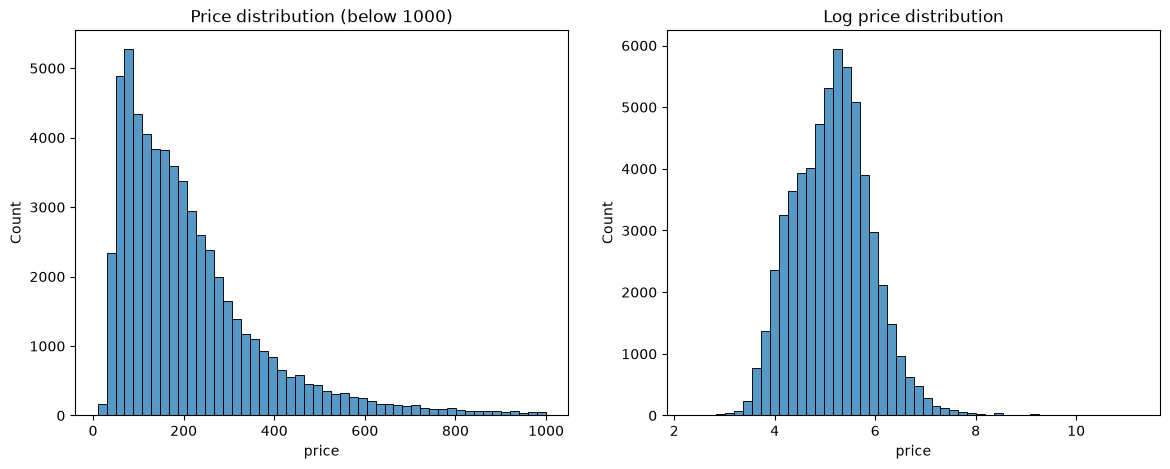

In [15]:
fig, ax = plt.subplots(ncols=2, figsize=(14, 5))
sns.histplot(df[df['price'] < 1000]['price'], bins=50, ax=ax[0])
ax[0].set_title('Price distribution (below 1000)')
sns.histplot(np.log(df['price']), bins=50, ax=ax[1])
ax[1].set_title('Log price distribution')
plt.savefig('figures/price_distribution.png', bbox_inches='tight')
plt.show()

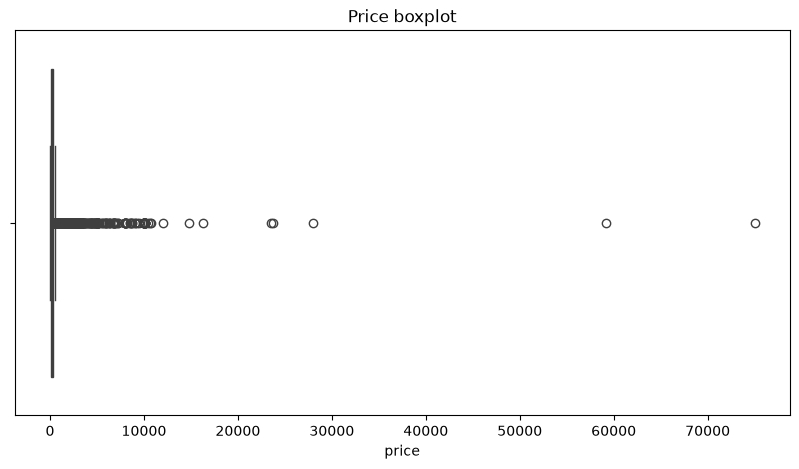

In [16]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['price'])
plt.title('Price boxplot')
plt.savefig('figures/price_boxplot.png', bbox_inches='tight')
plt.show()

### 2.5 Price by groups

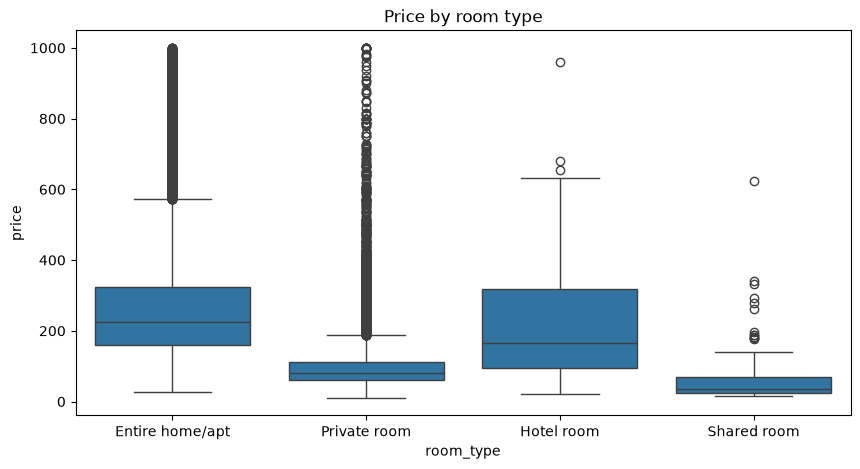

In [17]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='room_type', y='price', data=df[df['price'] < 1000])
plt.title('Price by room type')
plt.savefig('figures/price_room_type.png', bbox_inches='tight')
plt.show()

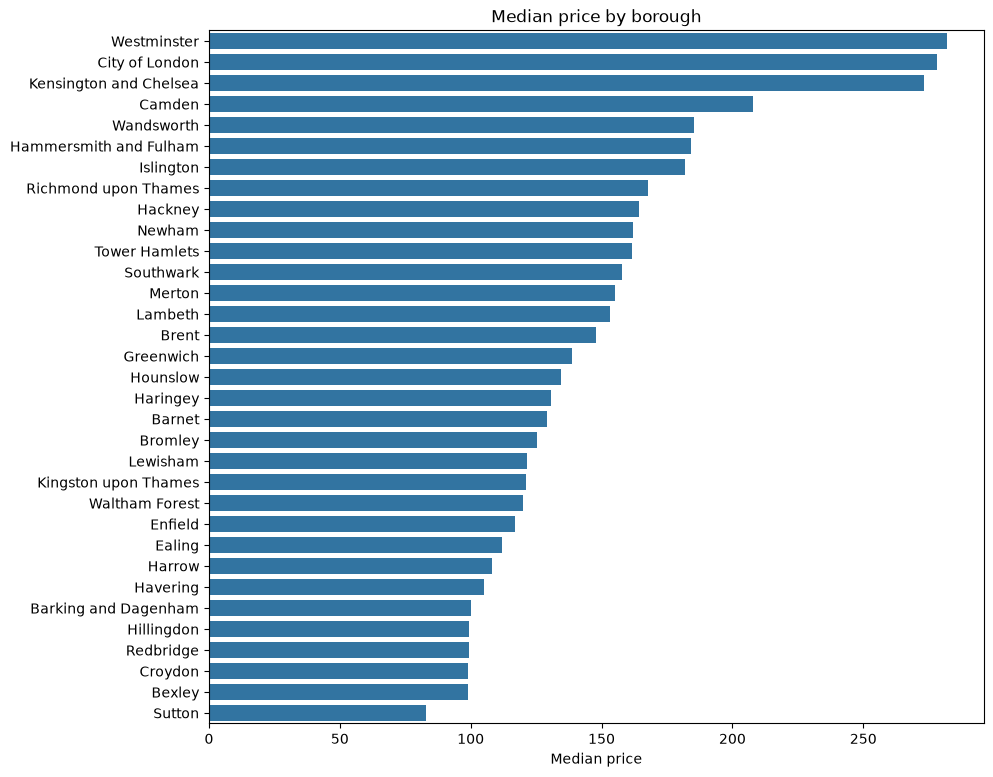

In [18]:
borough_price = df.groupby('neighbourhood_cleansed')['price'].median().sort_values(ascending=False)
plt.figure(figsize=(10, 9))
sns.barplot(x=borough_price.values, y=borough_price.index)
plt.title('Median price by borough')
plt.xlabel('Median price')
plt.ylabel('')
plt.savefig('figures/price_borough.png', bbox_inches='tight')
plt.show()

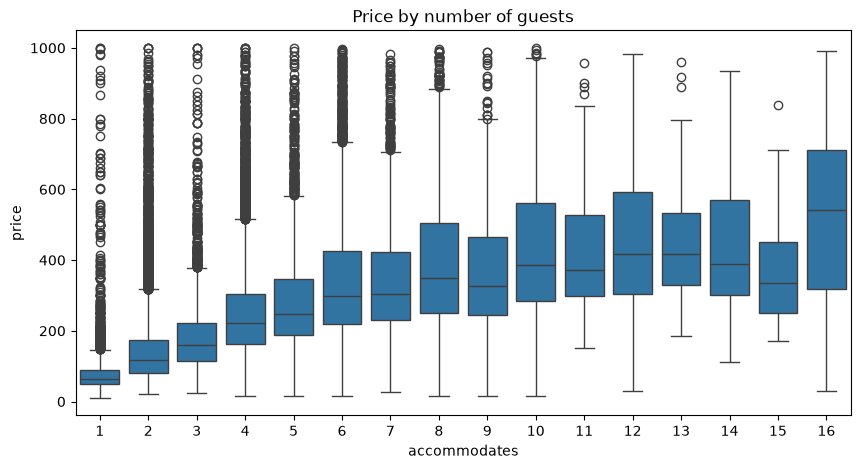

In [19]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='accommodates', y='price', data=df[df['price'] < 1000])
plt.title('Price by number of guests')
plt.savefig('figures/price_accommodates.png', bbox_inches='tight')
plt.show()

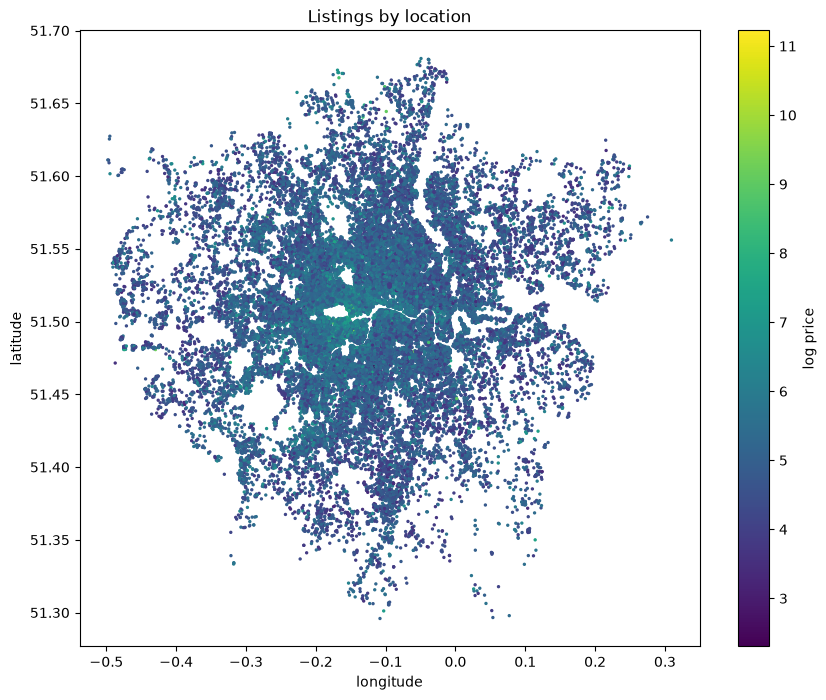

In [20]:
plt.figure(figsize=(10, 8))
plt.scatter(df['longitude'], df['latitude'], c=np.log(df['price']), s=2, cmap='viridis')
plt.colorbar(label='log price')
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.title('Listings by location')
plt.savefig('figures/map.png', bbox_inches='tight')
plt.show()

### 2.6 Correlation matrix

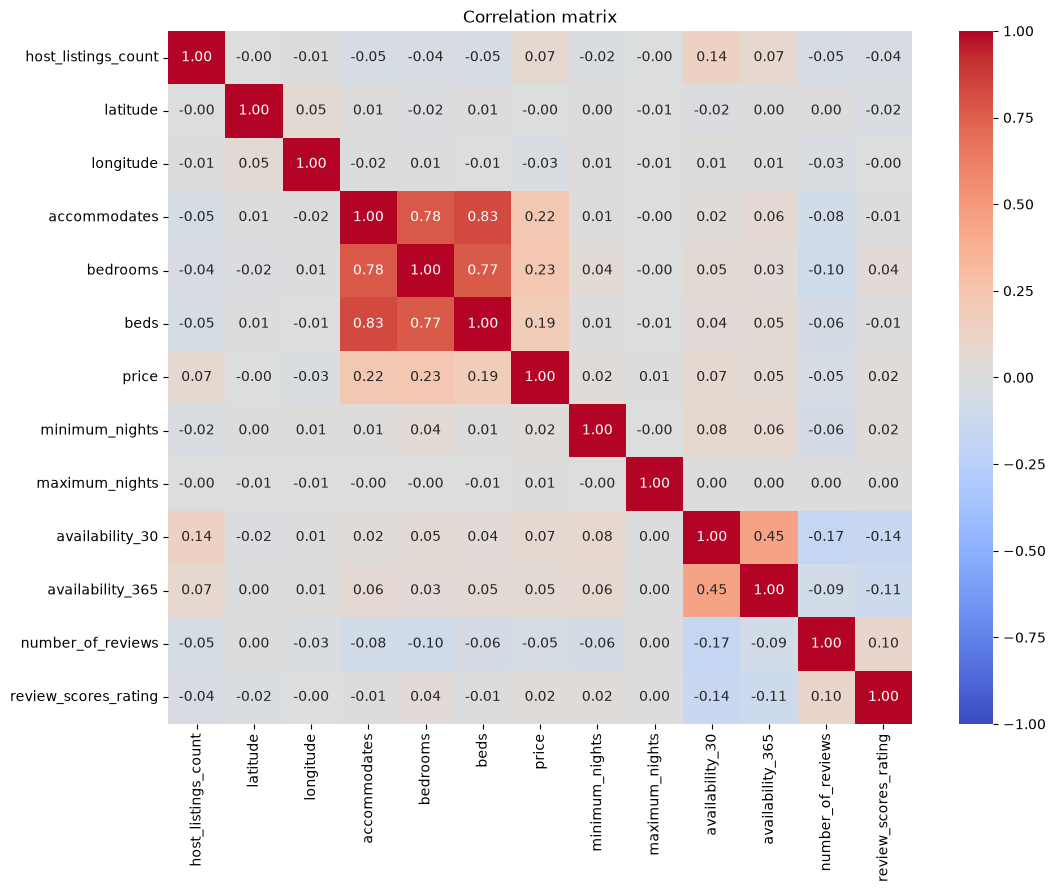

In [21]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.select_dtypes(include='number').drop(columns=['id']).corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.savefig('figures/correlation.png', bbox_inches='tight')
plt.show()

In [22]:
corr_df = df.select_dtypes(include='number').drop(columns=['id'])
corr_df['price'] = np.log(corr_df['price'])
corr_df.corr()['price'].sort_values(ascending=False)

price                   1.000000
accommodates            0.609027
bedrooms                0.512303
beds                    0.467068
host_listings_count     0.137478
availability_365        0.064431
review_scores_rating    0.060271
availability_30         0.050434
maximum_nights          0.015709
latitude                0.010308
minimum_nights         -0.007611
longitude              -0.082478
number_of_reviews      -0.125566
Name: price, dtype: float64